# Calisma 1 - Pnomotoraks BT icin Cok Ajanli (Multi-Agent) Karar Destek Sistemi

Bu notebook, ilk makaledeki (Biomedicines, U-Net + SAM2 + VLM) **tek gecisli** pipeline'i
dort uzman ajandan ve bir orkestratorden olusan **geri beslemeli** bir sisteme donusturur:

| Ajan | Gorev | Kullandigi arac |
|---|---|---|
| **A1 - Tarama (Triage)** | Kesitte pnomotoraks olasiligini hizla siniflar: negatif / belirsiz / pozitif. Negatif kesitlerde pahali adimlar (SAM2, VLM) atlanir. | U-Net olasilik haritasi |
| **A2 - Segmentasyon** | Maskeyi uretir; dogrulama ajanindan geri bildirim gelirse **farkli prompt stratejisiyle** yeniden dener (SAM2 goruntu gomulmesi bir kez hesaplanir, tekrarlar ucuzdur). | U-Net + SAM2 |
| **A3 - Dogrulama** | Maskenin anatomik/istatistiksel olabilirligini kontrol eder (U-Net-SAM2 uyumu, govde icinde olma, hava yogunlugu, alan araligi, guven). Hasta duzeyinde kesitler arasi **taraf tutarliligini** denetler. Basarisiz kesitleri A2'ye geri gonderir, cozulemeyenleri "insan incelemesi gerekli" diye isaretler. | Kural tabanli denetleyiciler |
| **A4 - Raporlama** | Hasta duzeyinde yapilandirilmis rapor + VLM serbest metni yazar; **olgu denetimi (fact-check)** ile VLM metnindeki taraf/yayginlik celiskilerini ve konu disi terimleri yakalar, gerekirse yeniden urettirir. | Qwen2-VL + kural tabanli denetleyici |

Deney tasarimi:
* **Temel model (baseline):** ilk makaledeki pipeline (birebir ayni kod, `po.baseline_pipeline`).
* **Onerilen sistem:** tum ajanlar acik.
* **Ablasyon:** her ajan/ozellik tek tek kapatilir.
* Esik/parametre ayari yalnizca **dogrulama (val)** hastalarinda yapilir; **test** hastalari ilk makaleyle aynidir ve yalnizca raporlama icin kullanilir.
* Degerlendirme 224x224 parcalar uzerinde degil, **tam kesitler** (885x885) uzerinde yapilir (klinik kullanim senaryosu).
* **Veri ozelligi:** kesitlerin neredeyse tamami (852/853) pnomotoraks pozitiftir. Bu nedenle kesit/hasta duzeyi ozgulluk
  anlamli degildir; ozgulluk **yari-toraks duzeyinde** (GT'de pnomotoraks olmayan karsi taraf = negatif) ve piksel duzeyinde
  (kesinlik/precision, HD95) raporlanir. Tarama duzeyi ozgulluk Calisma 3'te negatif taramalarla olculur.

**Calistirmadan once:** Ilk makalede egitilmis
`pnomotoraks_unet.pth` agirligi `MyDrive/pnomotoraks_v3_artifacts/` altinda olmalidir (yeniden egitim yapilmaz).

In [1]:
!pip install -q segmentation_models_pytorch opencv-python-headless pillow scipy matplotlib pandas scikit-learn
!pip install -q 'transformers>=4.46.0' accelerate qwen-vl-utils
!rm -rf /content/sam2
!git clone -q https://github.com/facebookresearch/sam2.git /content/sam2
%cd /content/sam2
!SAM2_BUILD_CUDA=0 pip install -q -e .
!mkdir -p checkpoints
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_small.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
%cd /content

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 48.2 MB/s eta 0:00:00
/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 13.9 MB/s eta 0:00:00
  Building editable for SAM-2 (pyproject.toml) ... done
/content


### Ortak yardimci modul
Asagidaki hucre `pnx_ortak.py` dosyasini Colab diskine yazar (ilk makaledeki fonksiyonlarin aynisi). Degistirmeniz gerekmez.

In [2]:
%%writefile /content/pnx_ortak.py
# -*- coding: utf-8 -*-
"""
pnx_ortak.py - Uc yeni calismanin (Calisma 1/2/3) ortak yardimci modulu.

Pnomotoraks_sonuc3.ipynb notebook'undaki veri hazirlama, hasta bazli bolme,
U-Net cikarimi (sliding window), SAM2 sinir iyilestirme, birlestirme kurali,
guvenilirlik katsayisi ve metrik fonksiyonlarinin AYNISI buraya tasinmistir.
Boylece uc calisma da:
  * ayni egitilmis U-Net agirligini (pnomotoraks_unet.pth) yeniden egitmeden kullanir,
  * ayni tohumla (SEED=42) ayni train/val/test hasta bolmesini uretir
    (test hastalari ilk makaledekiyle birebir aynidir, sizinti olmaz),
  * ilk makaledeki pipeline'i "temel model" (baseline) olarak birebir yeniden uretir.

Colab'da kullanim:
    import sys; sys.path.insert(0, '/content/drive/MyDrive/pnx_kod')
    import pnx_ortak as po
    po.init_unet(); po.init_sam2_image()
"""
import os, glob, random, time
import numpy as np
import cv2
import torch
from PIL import Image
from scipy import ndimage

# ---------------------------------------------------------------------------
# Yapilandirma (ilk makaleyle ayni degerler)
# ---------------------------------------------------------------------------
RAW_DIR = '/content/drive/MyDrive/CT_goruntuler_anon'
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/pnomotoraks_v3_artifacts'
UNET_WEIGHT_PATH = f'{DRIVE_BACKUP_DIR}/pnomotoraks_unet.pth'

SAM2_REPO_DIR = '/content/sam2'
SAM2_CHECKPOINT = '/content/sam2/checkpoints/sam2.1_hiera_small.pt'
SAM2_CONFIG = 'configs/sam2.1/sam2.1_hiera_s.yaml'

IMAGE_SIZE = 224
PATCH_STRIDE = 224
SEED = 42
PNEUMOTHORAX_LABEL = 1
LUNG_LABEL = 2
TRAIN_RATIO = 0.65
VAL_RATIO = 0.10

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

unet_model = None
sam2_image_predictor = None
_sam2_base_model = None

# Segmentasyon modeli ve son isleme ayarlari. Varsayilanlar ilk makaleyle (Biomedicines) birebir aynidir:
# 224x224 parca U-Net, esik 0.5, 80 pikselden kucuk bilesenleri at, YALNIZCA en buyuk bileseni tut.
# Calisma1b (metrik guclendirme) val setinde daha iyi ayarlari secip guclu_segmenter.json'a yazar;
# load_segmenter_config() ile tum calismalar ayni ayari kullanabilir.
SEG = {
    'kind': 'unet_patch',     # 'unet_patch' (ilk makale) | 'guclu' (tam cozunurluk, cok gorevli model)
    'threshold': 0.5,
    'min_area': 80,
    'keep': 'largest',        # 'largest' | 'all' | 'top2'
    'tta': False,             # yatay cevirme ile test-zamani artirma
    'lung_filter': False,     # yalnizca 'guclu': akciger olasiligi yuksek bolgeye dusen pnomotoraks bilesenlerini at
}
strong_model = None
LAST_LUNG_PROB = None


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# Veri: hasta indeksi ve hasta bazli bolme (sonuc3 Hucre 4-5 ile birebir ayni)
# ---------------------------------------------------------------------------
def _slice_sort_key(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    return (0, int(stem)) if stem.isdigit() else (1, stem)


def find_pairs_for_patient(patient_dir, numeric_order=False):
    # numeric_order=False: ilk makaledeki gibi alfabetik siralama (bolme ayni kalsin diye).
    # numeric_order=True : kesitleri sayisal sirada dondurur (video/sekans calismalari icin;
    #                      '10.jpg' '2.jpg'den once gelmesin).
    pairs = []
    jpg_files = sorted(glob.glob(os.path.join(patient_dir, '*.jpg')))
    if numeric_order:
        jpg_files = sorted(jpg_files, key=_slice_sort_key)
    for jpg_path in jpg_files:
        stem = os.path.splitext(os.path.basename(jpg_path))[0]
        png_path = os.path.join(patient_dir, stem + '.png')
        if os.path.exists(png_path):
            pairs.append((jpg_path, png_path))
    return pairs


def build_patient_split(raw_dir=RAW_DIR, seed=SEED, numeric_order=True):
    """Ilk makaledeki hasta bazli bolmeyi birebir yeniden uretir.

    Donus: patient_index {pid: [(jpg, png), ...]}, split_of_patient {pid: 'train'|'val'|'test'}
    """
    patient_dirs = sorted([d for d in glob.glob(os.path.join(raw_dir, '*')) if os.path.isdir(d)])
    patient_index = {}
    for pdir in patient_dirs:
        pid = os.path.basename(pdir)
        pairs = find_pairs_for_patient(pdir, numeric_order=numeric_order)
        if len(pairs) > 0:
            patient_index[pid] = pairs

    patient_ids = sorted(patient_index.keys())
    rng = random.Random(seed)
    rng.shuffle(patient_ids)
    n = len(patient_ids)
    n_train = int(round(n * TRAIN_RATIO))
    n_val = int(round(n * VAL_RATIO))
    split_of_patient = {}
    for pid in patient_ids[:n_train]:
        split_of_patient[pid] = 'train'
    for pid in patient_ids[n_train:n_train + n_val]:
        split_of_patient[pid] = 'val'
    for pid in patient_ids[n_train + n_val:]:
        split_of_patient[pid] = 'test'
    return patient_index, split_of_patient


def load_image_rgb(image_path):
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_label_map(mask_path):
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    return m


def load_binary_mask(mask_path, label=PNEUMOTHORAX_LABEL):
    return (load_label_map(mask_path) == label).astype(np.uint8)


# ---------------------------------------------------------------------------
# Morfolojik yardimcilar ve rapor yardimcilari (sonuc3 Hucre 19)
# ---------------------------------------------------------------------------
def clean_mask(mask, min_area=80):
    mask = (mask > 0).astype(np.uint8)
    labeled, num = ndimage.label(mask)
    out = np.zeros_like(mask, dtype=np.uint8)
    for i in range(1, num + 1):
        region = (labeled == i)
        if region.sum() >= min_area:
            out[region] = 1
    return out


def largest_component(mask):
    labeled, num = ndimage.label(mask)
    if num == 0:
        return mask.astype(np.uint8)
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    return (labeled == (int(np.argmax(sizes)) + 1)).astype(np.uint8)


def keep_components(mask, keep=None):
    keep = SEG['keep'] if keep is None else keep
    mask = (mask > 0).astype(np.uint8)
    if keep == 'largest':
        return largest_component(mask)
    if keep == 'top2':
        labeled, num = ndimage.label(mask)
        if num <= 2:
            return mask
        sizes = ndimage.sum(mask, labeled, range(1, num + 1))
        top = np.argsort(sizes)[::-1][:2] + 1
        return np.isin(labeled, top).astype(np.uint8)
    return mask


def postprocess_mask(mask, min_area=None, keep=None):
    """Ikili maskeye SEG ayarlarina gore kucuk bilesen temizligi + bilesen politikasi uygular."""
    return keep_components(clean_mask(mask, SEG['min_area'] if min_area is None else min_area), keep)


def area_ratio(mask):
    return float(mask.sum() / mask.size)


def estimate_side(mask, radiological_convention=True):
    """Pnomotoraksin tarafini tahmin eder.

    DIKKAT: Aksiyel BT goruntuleri radyolojik konvansiyonda gosterilir; goruntunun
    SOL yarisi hastanin SAG tarafidir. Ilk makaledeki kodda (sonuc3) goruntunun sol
    yarisi 'sol' olarak etiketleniyordu (radyolojik konvansiyon dikkate alinmamisti).
    Yeni calismalarda varsayilan olarak radyolojik konvansiyon kullanilir; ilk
    makaleyle birebir karsilastirma gerekirse radiological_convention=False verin.
    """
    if mask.sum() == 0:
        return 'belirgin degil'
    h, w = mask.shape
    img_left = mask[:, :w // 2].sum()
    img_right = mask[:, w // 2:].sum()
    if radiological_convention:
        side_of_img_left, side_of_img_right = 'sag', 'sol'
    else:
        side_of_img_left, side_of_img_right = 'sol', 'sag'
    if img_left > img_right * 1.2:
        return side_of_img_left
    elif img_right > img_left * 1.2:
        return side_of_img_right
    return 'bilateral'


def estimate_extent(mask):
    r = area_ratio(mask)
    if r < 0.005:
        return 'cok kucuk'
    elif r < 0.02:
        return 'kucuk'
    elif r < 0.06:
        return 'orta'
    return 'genis'


def make_overlay(image_np, mask, color=(255, 0, 0), alpha=0.35):
    overlay = image_np.copy()
    m = mask.astype(bool)
    col = np.array(color, dtype=np.float32)
    overlay[m] = ((1 - alpha) * overlay[m] + alpha * col).astype(np.uint8)
    return overlay


def mask_iou(mask_a, mask_b):
    inter = np.logical_and(mask_a > 0, mask_b > 0).sum()
    union = np.logical_or(mask_a > 0, mask_b > 0).sum()
    return 0.0 if union == 0 else float(inter) / float(union)


def mask_box(mask, margin=10):
    h, w = mask.shape
    ys, xs = np.where(mask > 0)
    return np.array([max(0, xs.min() - margin), max(0, ys.min() - margin),
                     min(w - 1, xs.max() + margin), min(h - 1, ys.max() + margin)])


# ---------------------------------------------------------------------------
# Metrikler (sonuc3 Hucre 12)
# ---------------------------------------------------------------------------
def segmentation_metrics(pred_mask, gt_mask, eps=1e-6):
    p = pred_mask.flatten().astype(np.uint8)
    g = gt_mask.flatten().astype(np.uint8)
    tp = int(np.sum((p == 1) & (g == 1)))
    tn = int(np.sum((p == 0) & (g == 0)))
    fp = int(np.sum((p == 1) & (g == 0)))
    fn = int(np.sum((p == 0) & (g == 1)))
    sens = (tp + eps) / (tp + fn + eps)
    prec = (tp + eps) / (tp + fp + eps)
    return {
        'dice': (2 * tp + eps) / (2 * tp + fp + fn + eps),
        'iou': (tp + eps) / (tp + fp + fn + eps),
        'accuracy': (tp + tn + eps) / (tp + tn + fp + fn + eps),
        'sensitivity': sens,
        'specificity': (tn + eps) / (tn + fp + eps),
        'precision': prec,
        'f1': (2 * prec * sens + eps) / (prec + sens + eps),
    }


def hd95_pixels(pred_mask, gt_mask):
    pred_mask = (pred_mask > 0).astype(np.uint8)
    gt_mask = (gt_mask > 0).astype(np.uint8)
    if pred_mask.sum() == 0 or gt_mask.sum() == 0:
        return float('nan')
    pb = pred_mask - ndimage.binary_erosion(pred_mask).astype(np.uint8)
    gb = gt_mask - ndimage.binary_erosion(gt_mask).astype(np.uint8)
    if pb.sum() == 0 or gb.sum() == 0:
        return float('nan')
    gt_dt = ndimage.distance_transform_edt(1 - gb)
    pr_dt = ndimage.distance_transform_edt(1 - pb)
    return float(max(np.percentile(gt_dt[pb > 0], 95), np.percentile(pr_dt[gb > 0], 95)))


def hemithorax_counts(pred_mask, gt_mask, min_pixels=50):
    """Yari-toraks (goruntunun sol/sag yarisi) duzeyinde tespit sayimlari.

    Veri setindeki kesitlerin neredeyse tamami pnomotoraks pozitiftir (852/853), bu yuzden kesit
    duzeyinde ozgulluk olculemez. Pnomotoraks cogunlukla tek tarafli oldugundan, GT'de pnomotoraks
    olmayan karsi yari-toraks dogal bir negatif ornektir; burada tahmin edilen maske varsa yanlis pozitiftir.
    Donus: {'tp','fn','tn','fp'} (iki yari uzerinden toplam)."""
    w = gt_mask.shape[1]
    c = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
    for sl in (slice(0, w // 2), slice(w // 2, w)):
        g = gt_mask[:, sl].sum() >= min_pixels
        p = pred_mask[:, sl].sum() >= min_pixels
        c['tp' if g and p else 'fn' if g else 'fp' if p else 'tn'] += 1
    return c


def dice_3d(pred_vol, gt_vol, eps=1e-6):
    p = pred_vol > 0
    g = gt_vol > 0
    inter = np.logical_and(p, g).sum()
    return float((2 * inter + eps) / (p.sum() + g.sum() + eps))


def bootstrap_ci(values, n_boot=2000, alpha=0.05, seed=SEED):
    values = np.asarray([v for v in values if not np.isnan(v)])
    if len(values) == 0:
        return float('nan'), float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)]
    return float(values.mean()), float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


# ---------------------------------------------------------------------------
# U-Net (sonuc3 Hucre 11 + 19)
# ---------------------------------------------------------------------------
def init_unet(weight_path=UNET_WEIGHT_PATH):
    global unet_model
    import segmentation_models_pytorch as smp
    unet_model = smp.Unet(encoder_name='mobilenet_v2', encoder_weights=None,
                          in_channels=3, classes=1, activation=None).to(DEVICE)
    unet_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    unet_model.eval()
    print('U-Net yuklendi:', weight_path)
    return unet_model


_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def _to_tensor(patch_rgb):
    x = (patch_rgb.astype(np.float32) / 255.0 - _MEAN) / _STD
    return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0)


def unet_prob_map(image_np, tta=None):
    """Aktif segmentasyon modeliyle tam goruntu pnomotoraks olasilik haritasi (HxW, 0-1).
    SEG['kind'] == 'guclu' ise tam cozunurluk modeli, aksi halde ilk makaledeki parca U-Net kullanilir."""
    global LAST_LUNG_PROB
    tta = SEG['tta'] if tta is None else tta
    fn = _strong_prob if SEG['kind'] == 'guclu' else _patch_unet_prob_map
    p, lung = fn(image_np)
    if tta:
        p2, lung2 = fn(np.ascontiguousarray(image_np[:, ::-1]))
        p = (p + p2[:, ::-1]) / 2
        if lung is not None:
            lung = (lung + lung2[:, ::-1]) / 2
    LAST_LUNG_PROB = lung
    return p


@torch.no_grad()
def _strong_prob(image_np):
    h, w = image_np.shape[:2]
    H, W = int(np.ceil(h / 32) * 32), int(np.ceil(w / 32) * 32)
    img = cv2.copyMakeBorder(image_np, 0, H - h, 0, W - w, cv2.BORDER_CONSTANT, value=0)
    x = _to_tensor(img).to(DEVICE)
    with torch.autocast('cuda', enabled=(DEVICE == 'cuda')):
        out = torch.sigmoid(strong_model(x).float())[0].cpu().numpy()
    lung = out[1, :h, :w] if out.shape[0] > 1 else None
    return out[0, :h, :w], lung


def init_strong_model(weight_path, arch='Unet', encoder='resnet34', classes=2):
    global strong_model
    import segmentation_models_pytorch as smp
    strong_model = getattr(smp, arch)(encoder_name=encoder, encoder_weights=None, in_channels=3, classes=classes).to(DEVICE)
    strong_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    strong_model.eval()
    SEG['kind'] = 'guclu'
    print('Guclu segmentasyon modeli yuklendi:', weight_path, arch, encoder)
    return strong_model


def load_segmenter_config(path):
    """Calisma1b'nin urettigi guclu_segmenter.json'u yukler (model + val'de secilen son isleme)."""
    import json as _json
    cfg = _json.load(open(path))
    if cfg.get('kind') == 'guclu':
        init_strong_model(cfg['weight_path'], cfg.get('arch', 'Unet'), cfg.get('encoder', 'resnet34'))
    elif unet_model is None:
        init_unet()
    for k in ('kind', 'threshold', 'min_area', 'keep', 'tta', 'lung_filter'):
        if k in cfg:
            SEG[k] = cfg[k]
    print('Segmenter ayari:', SEG)
    return cfg


@torch.no_grad()
def _patch_unet_prob_map(image_np, patch_size=IMAGE_SIZE, stride=PATCH_STRIDE, batch_size=16):
    """Kaydirmali pencere ile tam goruntu olasilik haritasi (HxW, 0-1) - ilk makaledeki U-Net."""
    h, w = image_np.shape[:2]
    ys = [0] if h <= patch_size else sorted(set(list(range(0, h - patch_size, stride)) + [h - patch_size]))
    xs = [0] if w <= patch_size else sorted(set(list(range(0, w - patch_size, stride)) + [w - patch_size]))
    prob_map = np.zeros((h, w), dtype=np.float32)
    count_map = np.zeros((h, w), dtype=np.float32)
    coords, tensors = [], []
    for y in ys:
        for x in xs:
            patch = image_np[y:y + patch_size, x:x + patch_size]
            ph, pw = patch.shape[:2]
            if ph < patch_size or pw < patch_size:
                patch = cv2.copyMakeBorder(patch, 0, patch_size - ph, 0, patch_size - pw, cv2.BORDER_CONSTANT, value=0)
            coords.append((y, x, ph, pw))
            tensors.append(_to_tensor(patch))
    for i in range(0, len(tensors), batch_size):
        batch = torch.cat(tensors[i:i + batch_size]).to(DEVICE)
        probs = torch.sigmoid(unet_model(batch))[:, 0].cpu().numpy()
        for (y, x, ph, pw), pr in zip(coords[i:i + batch_size], probs):
            prob_map[y:y + ph, x:x + pw] += pr[:ph, :pw]
            count_map[y:y + ph, x:x + pw] += 1.0
    count_map[count_map == 0] = 1.0
    return prob_map / count_map, None


def mask_from_prob(prob, lung_prob=None, threshold=None, min_area=None, keep=None, lung_filter=None):
    threshold = SEG['threshold'] if threshold is None else threshold
    lung_filter = SEG['lung_filter'] if lung_filter is None else lung_filter
    m = clean_mask((prob > threshold).astype(np.uint8), SEG['min_area'] if min_area is None else min_area)
    if lung_filter and lung_prob is not None and m.sum() > 0:
        # Pnomotoraks akciger parankiminin DISINDA (plevral bosluk) yer alir; akciger olasiligi
        # yuksek bolgeyle cogunlukla ortusen bilesenler yanlis pozitif kabul edilir.
        lab, n = ndimage.label(m)
        for j in range(1, n + 1):
            reg = lab == j
            if lung_prob[reg].mean() > 0.5:
                m[reg] = 0
    return keep_components(m, keep)


def unet_predict(image_np, threshold=None):
    """sonuc3'teki unet_predict_external ile ayni cikti: (maske, guven, olasilik haritasi).
    Varsayilan SEG ayarlariyla ilk makaleyle birebir ayni sonucu verir."""
    prob = unet_prob_map(image_np)
    mask = mask_from_prob(prob, LAST_LUNG_PROB, threshold=threshold)
    return mask, float(prob.max()), prob


# ---------------------------------------------------------------------------
# SAM2 (goruntu modu; sonuc3 Hucre 18-19)
# ---------------------------------------------------------------------------
def _sam2_import():
    import sys
    if SAM2_REPO_DIR not in sys.path:
        sys.path.insert(0, SAM2_REPO_DIR)


def init_sam2_image():
    global sam2_image_predictor, _sam2_base_model
    _sam2_import()
    from sam2.build_sam import build_sam2
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    _sam2_base_model = build_sam2(config_file=SAM2_CONFIG, ckpt_path=SAM2_CHECKPOINT, device=DEVICE)
    sam2_image_predictor = SAM2ImagePredictor(_sam2_base_model)
    print('SAM2 (goruntu modu) hazir.')
    return sam2_image_predictor


def init_sam2_video(offload_video_to_cpu=False):
    _sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    vp = build_sam2_video_predictor(SAM2_CONFIG, SAM2_CHECKPOINT, device=DEVICE)
    print('SAM2 (video modu) hazir.')
    return vp


@torch.no_grad()
def sam2_set_image(image_np):
    sam2_image_predictor.set_image(image_np)


@torch.no_grad()
def sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10, multimask_select='score',
                 image_already_set=False):
    """SAM2 goruntu modu tahmini.

    prompt_type: 'box' | 'point' | 'box+point'
    multimask_select: 'score' (ilk makaledeki gibi en yuksek SAM skoru) |
                      'agreement' (U-Net maskesiyle en yuksek IoU'lu aday)
    SEG['keep'] != 'largest' ise U-Net maskesinin her bagli bileseni (or. iki tarafli pnomotoraks)
    icin ayri istem verilir ve sonuclar birlestirilir.
    """
    if not image_already_set:
        sam2_image_predictor.set_image(image_np)
    if SEG['keep'] != 'largest' and unet_mask.sum() > 0:
        lab, n = ndimage.label(unet_mask > 0)
        if n > 1:
            out, skorlar, alanlar = np.zeros_like(unet_mask, dtype=np.uint8), [], []
            for j in range(1, n + 1):
                comp = (lab == j).astype(np.uint8)
                m, s = _sam2_tek(image_np, comp, prompt_type, box_margin, multimask_select)
                out = np.logical_or(out, m).astype(np.uint8)
                skorlar.append(s); alanlar.append(comp.sum())
            return keep_components(out), float(np.average(skorlar, weights=alanlar))
    return _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select)


def _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select):
    h, w = image_np.shape[:2]
    has_mask = unet_mask.sum() > 0
    box = mask_box(unet_mask, box_margin) if has_mask else np.array([int(w * .05), int(h * .05), int(w * .95), int(h * .95)])
    if has_mask:
        ys, xs = np.where(unet_mask > 0)
        # Agirlik merkezi maskenin disina dusebilir (hilal seklindeki pnomotoraks);
        # bu yuzden maske icinde merkeze en yakin piksel kullanilir.
        cy, cx = ys.mean(), xs.mean()
        j = int(np.argmin((ys - cy) ** 2 + (xs - cx) ** 2))
        point = np.array([[int(xs[j]), int(ys[j])]])
    else:
        point = np.array([[w // 2, h // 2]])

    kwargs = dict(multimask_output=True)
    if prompt_type == 'box':
        kwargs.update(point_coords=None, point_labels=None, box=box)
    elif prompt_type == 'point':
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=None)
    else:
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=box)
    masks, scores, _ = sam2_image_predictor.predict(**kwargs)

    # Tek bir bilesen/istem icin SAM2 cikti adayinin en buyuk bileseni alinir (ilk makaleyle ayni).
    cands = [largest_component(clean_mask(m.astype(np.uint8))) for m in masks]
    if multimask_select == 'agreement' and has_mask:
        best = int(np.argmax([mask_iou(c, unet_mask) for c in cands]))
    else:
        best = int(np.argmax(scores))
    return cands[best], float(scores[best])


def combine_masks(unet_mask, sam_mask, min_agreement_iou=0.3):
    # sonuc3 Hucre 19 ile ayni kural: U-Net negatifse bos; uyum dusukse U-Net'e geri dus.
    # Bilesen politikasi SEG['keep'] ile belirlenir (varsayilan 'largest' = ilk makale).
    if unet_mask.sum() == 0:
        return np.zeros_like(sam_mask, dtype=np.uint8)
    if mask_iou(unet_mask, sam_mask) < min_agreement_iou:
        return postprocess_mask(unet_mask)
    return postprocess_mask(np.logical_or(unet_mask > 0, sam_mask > 0).astype(np.uint8))


def compute_reliability(unet_conf, sam_conf, final_mask, wU=0.35, wS=0.45, wA=0.20):
    area_term = min(area_ratio(final_mask) / 0.03, 1.0)
    return float(max(0.0, min(1.0, wU * unet_conf + wS * sam_conf + wA * area_term)))


def baseline_pipeline(image_np):
    """Ilk makaledeki (Biomedicines) tek gecisli pipeline: U-Net -> SAM2 kutu -> birlestirme."""
    t0 = time.time()
    unet_mask, unet_conf, prob = unet_predict(image_np)
    sam_mask, sam_conf = sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10)
    final = combine_masks(unet_mask, sam_mask)
    return {
        'mask': final, 'unet_mask': unet_mask, 'sam_mask': sam_mask,
        'unet_conf': unet_conf, 'sam_conf': sam_conf, 'prob': prob,
        'reliability': compute_reliability(unet_conf, sam_conf, final),
        'time_s': time.time() - t0,
    }


# ---------------------------------------------------------------------------
# Anatomik olabilirlik yardimcilari (Calisma 1 dogrulama ajani icin)
# ---------------------------------------------------------------------------
def body_mask(image_np, thr=20):
    """Govde (vucut) maskesi: goruntu esiklenir, en buyuk bilesen alinir, delikleri doldurulur.
    Pnomotoraks havasi govde ICINDE, hasta disindaki hava govde DISINDA kalir."""
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    m = (gray > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    m = largest_component(m)
    return ndimage.binary_fill_holes(m).astype(np.uint8)


def mean_intensity_in_mask(image_np, mask):
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    return float(gray[mask > 0].mean()) if mask.sum() > 0 else float('nan')


# ---------------------------------------------------------------------------
# VLM (Qwen2-VL; sonuc3 Hucre 30-31)
# ---------------------------------------------------------------------------
vlm_model = None
vlm_processor = None
VLM_MODEL_ID = 'Qwen/Qwen2-VL-2B-Instruct'


def init_vlm(model_id=VLM_MODEL_ID):
    global vlm_model, vlm_processor, VLM_MODEL_ID
    from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
    VLM_MODEL_ID = model_id
    vlm_model = Qwen2VLForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.float16, device_map='auto')
    vlm_processor = AutoProcessor.from_pretrained(model_id)
    print('VLM hazir:', model_id)


@torch.no_grad()
def vlm_generate(image_pil, prompt_text, max_new_tokens=400, temperature=0.6, seed=None):
    from qwen_vl_utils import process_vision_info
    if seed is not None:
        torch.manual_seed(seed)
    messages = [{'role': 'user', 'content': [{'type': 'image', 'image': image_pil}, {'type': 'text', 'text': prompt_text}]}]
    chat = vlm_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = vlm_processor(text=[chat], images=image_inputs, videos=video_inputs, padding=True, return_tensors='pt').to(DEVICE)
    out = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True,
                             temperature=temperature, top_p=0.9, repetition_penalty=1.3)
    trimmed = [o[len(i):] for i, o in zip(inputs.input_ids, out)]
    return vlm_processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip()

Writing /content/pnx_ortak.py


In [3]:
import os, sys, json, time, re, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from sklearn.metrics import roc_auc_score

from google.colab import drive
drive.mount('/content/drive')

sys.path.insert(0, '/content')
import pnx_ortak as po

po.set_seed()
OUT_DIR = '/content/drive/MyDrive/pnx_calisma1'
os.makedirs(OUT_DIR, exist_ok=True)
print('Cihaz:', po.DEVICE)

Mounted at /content/drive
Cihaz: cuda


## 1. Hasta bazli bolme (ilk makaleyle birebir ayni) ve tam kesit listeleri

In [4]:
patient_index, split_of_patient = po.build_patient_split()
val_patients = sorted([p for p, s in split_of_patient.items() if s == 'val'])
test_patients = sorted([p for p, s in split_of_patient.items() if s == 'test'])
print(f'Toplam hasta: {len(patient_index)} | val: {len(val_patients)} | test: {len(test_patients)}')
print('Test kesit sayisi:', sum(len(patient_index[p]) for p in test_patients))

Toplam hasta: 171 | val: 17 | test: 43
Test kesit sayisi: 211


### Segmentasyon modeli secimi
* `GUCLU_SEGMENTER = True`: Calisma1b notebook'unda egitilen guclu model ve val setinde secilen son isleme
  (`pnx_calisma1b/guclu_segmenter.json`) kullanilir; sonuclar `pnx_calisma1_guclu/` klasorune yazilir.
* `GUCLU_SEGMENTER = False`: ilk makaledeki U-Net ve ayarlar (onceki `pnx_calisma1/` sonuclari).

In [5]:
GUCLU_SEGMENTER = True
SEGMENTER_JSON = '/content/drive/MyDrive/pnx_calisma1b/guclu_segmenter.json'
if GUCLU_SEGMENTER and os.path.exists(SEGMENTER_JSON):
    po.load_segmenter_config(SEGMENTER_JSON)
    OUT_DIR = '/content/drive/MyDrive/pnx_calisma1_guclu'
    os.makedirs(OUT_DIR, exist_ok=True)
else:
    if GUCLU_SEGMENTER:
        print('UYARI: guclu_segmenter.json bulunamadi, ilk makaledeki U-Net kullaniliyor. Once Calisma1b calistirin.')
    po.init_unet()
print('Sonuclar bu klasore yazilacak:', OUT_DIR)
po.init_sam2_image()

Guclu segmentasyon modeli yuklendi: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34.pth Unet resnet34
Segmenter ayari: {'kind': 'guclu', 'threshold': 0.3, 'min_area': 20, 'keep': 'all', 'tta': True, 'lung_filter': False}
Sonuclar bu klasore yazilacak: /content/drive/MyDrive/pnx_calisma1_guclu
SAM2 (goruntu modu) hazir.


## 2. Dogrulama (val) setinde parametre kalibrasyonu

Ajanlarin esikleri burada, **sadece val hastalarindan** veriyle belirlenir:
* **A1 esikleri:** `t_neg` = val setinde kesit duzeyinde duyarlilik >= %98 olacak sekilde en buyuk max-olasilik esigi
  (pozitif kesit kacirmamak oncelikli). `t_pos` = ozgulluk >= %95 saglayan en kucuk esik.
* **A3 sinirlari:** GT pnomotoraks maskelerinin ortalama yogunlugunun %95 persentili (hava yogunlugu ust siniri),
  alan oraninin %1-%99 persentil araligi.

In [6]:
val_rows = []
for pid in val_patients:
    for jpg, png in patient_index[pid]:
        img = po.load_image_rgb(jpg)
        gt = po.load_binary_mask(png)
        prob = po.unet_prob_map(img)
        body = po.body_mask(img)
        val_rows.append({
            'patient_id': pid, 'slice': os.path.basename(jpg),
            'max_prob': float(prob.max()), 'gt_pos': bool(gt.sum() > 0),
            'gt_area_ratio': po.area_ratio(gt) if gt.sum() > 0 else np.nan,
            'gt_mean_int': po.mean_intensity_in_mask(img, gt) if gt.sum() > 0 else np.nan,
            'gt_in_body': float((gt * body).sum() / max(gt.sum(), 1)) if gt.sum() > 0 else np.nan,
        })
val_df = pd.DataFrame(val_rows)
val_df.to_csv(f'{OUT_DIR}/val_kalibrasyon.csv', index=False)
print(val_df.describe())


def choose_triage_thresholds(df, min_sens=0.98, min_spec=0.95):
    y = df.gt_pos.values.astype(int)
    s = df.max_prob.values
    grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
    t_neg, t_pos = 0.05, 0.95
    for t in grid:
        sens = ((s >= t) & (y == 1)).sum() / max((y == 1).sum(), 1)
        if sens >= min_sens:
            t_neg = t
    for t in grid[::-1]:
        spec = ((s < t) & (y == 0)).sum() / max((y == 0).sum(), 1)
        if spec >= min_spec:
            t_pos = t
    t_pos = max(t_pos, t_neg)
    return float(t_neg), float(t_pos)


T_NEG, T_POS = choose_triage_thresholds(val_df)
pos_val = val_df[val_df.gt_pos]
CALIB = {
    # Not: val setinde negatif kesit yoksa t_pos ozgulluk kosulu saglanamaz ve varsayilan 0.95 kalir.
    't_neg': T_NEG, 't_pos': T_POS,
    'max_mean_intensity': float(np.nanpercentile(pos_val.gt_mean_int, 95)),
    'min_area': float(np.nanpercentile(pos_val.gt_area_ratio, 1)),
    'max_area': float(np.nanpercentile(pos_val.gt_area_ratio, 99)),
    'min_in_body': float(max(0.80, np.nanpercentile(pos_val.gt_in_body, 5))),
    'min_agreement_iou': 0.3,
    'min_reliability': 0.55,
    # Kacirma supheli bayragi: nihai maske bos ama U-Net olasilik haritasinda zayif iz (>= t_suphe) varsa
    # kesit insan incelemesine isaretlenir. Veride negatif kesit olmadigi icin bu esik val'de ayarlanamaz;
    # gercek negatiflerde yanlis alarm uretecegi icin makalede ayrica raporlanir.
    't_suphe': 0.01,
}
try:
    CALIB['val_auroc_maxprob'] = float(roc_auc_score(val_df.gt_pos.astype(int), val_df.max_prob))
except ValueError:
    CALIB['val_auroc_maxprob'] = float('nan')
json.dump(CALIB, open(f'{OUT_DIR}/kalibrasyon.json', 'w'), indent=2)
CALIB

        max_prob  gt_area_ratio  gt_mean_int  gt_in_body
count  85.000000      85.000000    85.000000        85.0
mean    0.942181       0.009603    57.404956         1.0
std     0.196410       0.014466    24.107324         0.0
min     0.003662       0.000093    22.641227         1.0
25%     0.999140       0.000908    36.882518         1.0
50%     0.999852       0.002437    53.503738         1.0
75%     0.999971       0.008769    76.471869         1.0
max     0.999993       0.056032   123.930526         1.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


{'t_neg': 0.05,
 't_pos': 0.95,
 'max_mean_intensity': 92.14881742946753,
 'min_area': 0.00014575858221912278,
 'max_area': 0.04928218583421109,
 'min_in_body': 1.0,
 'min_agreement_iou': 0.3,
 'min_reliability': 0.55,
 't_suphe': 0.01,
 'val_auroc_maxprob': nan}

## 3. Ajanlarin tanimi

Her ajan `calistir(...)` metodu olan bir siniftir ve orkestratorun tuttugu **mesaj gunlugune (trace)**
ne yaptigini yazar. Bu gunluk hem aciklanabilirlik (hangi kesitte neden yeniden deneme yapildi) hem de
makaledeki nitel sekiller icin kullanilir.

In [7]:
class Gunluk:
    def __init__(self):
        self.kayitlar = []

    def yaz(self, ajan, adim, **bilgi):
        kayit = {'ajan': ajan, 'adim': adim}
        for k, v in bilgi.items():
            if isinstance(v, (np.floating, np.integer)):
                v = v.item()
            kayit[k] = v
        self.kayitlar.append(kayit)


class TaramaAjani:
    """A1: U-Net olasilik haritasi ile kesit duzeyinde hizli on eleme."""
    ad = 'A1-Tarama'

    def __init__(self, t_neg, t_pos):
        self.t_neg, self.t_pos = t_neg, t_pos

    def calistir(self, img, gunluk):
        prob = po.unet_prob_map(img)
        mp = float(prob.max())
        karar = 'negatif' if mp < self.t_neg else ('pozitif' if mp >= self.t_pos else 'belirsiz')
        gunluk.yaz(self.ad, 'siniflama', max_prob=round(mp, 4), karar=karar)
        return karar, prob


class SegmentasyonAjani:
    """A2: U-Net + SAM2. Strateji listesi dogrulama ajanindan geri bildirim geldikce sirayla denenir."""
    ad = 'A2-Segmentasyon'
    STRATEJILER = [
        {'ad': 'kutu_pay10_skor', 'prompt_type': 'box', 'box_margin': 10, 'multimask_select': 'score'},   # ilk makale
        {'ad': 'kutu_pay10_uyum', 'prompt_type': 'box', 'box_margin': 10, 'multimask_select': 'agreement'},
        {'ad': 'kutu+nokta_pay10', 'prompt_type': 'box+point', 'box_margin': 10, 'multimask_select': 'agreement'},
        {'ad': 'kutu_pay25_uyum', 'prompt_type': 'box', 'box_margin': 25, 'multimask_select': 'agreement'},
        {'ad': 'nokta_uyum', 'prompt_type': 'point', 'box_margin': 10, 'multimask_select': 'agreement'},
    ]

    def __init__(self, min_agreement_iou=0.3):
        self.min_agreement_iou = min_agreement_iou
        self._img_id = None

    def unet_maskesi(self, prob, yasak_yari=None, lung=None):
        p = prob.copy()
        if yasak_yari is not None:            # hasta duzeyi taraf kisiti (A3'ten gelir)
            w = p.shape[1]
            if yasak_yari == 'goruntu_sol':
                p[:, :w // 2] = 0
            else:
                p[:, w // 2:] = 0
        # Esik, bilesen politikasi ve akciger filtresi po.SEG ayarlarindan gelir
        # (varsayilan = ilk makale: esik 0.5, yalnizca en buyuk bilesen).
        m = po.mask_from_prob(p, lung)
        return m, float(p.max())

    def calistir(self, img, img_id, prob, strateji_idx, gunluk, yasak_yari=None, lung=None):
        st = self.STRATEJILER[strateji_idx]
        unet_mask, unet_conf = self.unet_maskesi(prob, yasak_yari, lung)
        if unet_mask.sum() == 0:
            gunluk.yaz(self.ad, 'segmentasyon', strateji=st['ad'], sonuc='U-Net bos maske')
            return {'mask': unet_mask, 'unet_mask': unet_mask, 'sam_mask': unet_mask,
                    'unet_conf': unet_conf, 'sam_conf': 0.0, 'strateji': st['ad']}
        # SAM2 goruntu kodlayicisi her kesit icin bir kez calisir; tekrar denemeler sadece
        # prompt kod cozucusunu calistirir (hesaplama maliyeti dusuk).
        if self._img_id != img_id:
            po.sam2_set_image(img)
            self._img_id = img_id
        sam_mask, sam_conf = po.sam2_predict(img, unet_mask, prompt_type=st['prompt_type'],
                                             box_margin=st['box_margin'], multimask_select=st['multimask_select'],
                                             image_already_set=True)
        final = po.combine_masks(unet_mask, sam_mask, self.min_agreement_iou)
        gunluk.yaz(self.ad, 'segmentasyon', strateji=st['ad'], unet_conf=round(unet_conf, 4),
                   sam_conf=round(sam_conf, 4), uyum_iou=round(po.mask_iou(unet_mask, sam_mask), 4),
                   alan=round(po.area_ratio(final), 5))
        return {'mask': final, 'unet_mask': unet_mask, 'sam_mask': sam_mask,
                'unet_conf': unet_conf, 'sam_conf': sam_conf, 'strateji': st['ad']}


class DogrulamaAjani:
    """A3: kural tabanli olabilirlik denetimi + hasta duzeyi taraf tutarliligi."""
    ad = 'A3-Dogrulama'

    def __init__(self, calib):
        self.c = calib

    def kesit_denetle(self, img, seg, body, gunluk):
        m = seg['mask']
        if m.sum() == 0:
            gunluk.yaz(self.ad, 'kesit_denetimi', gecti=True, not_='bos maske (negatif karar)')
            return True, 1.0, []
        rel = po.compute_reliability(seg['unet_conf'], seg['sam_conf'], m)
        kontroller = {
            'uyum': po.mask_iou(seg['unet_mask'], seg['sam_mask']) >= self.c['min_agreement_iou'],
            'govde_ici': (m * body).sum() / m.sum() >= self.c['min_in_body'],
            'hava_yogunlugu': po.mean_intensity_in_mask(img, m) <= self.c['max_mean_intensity'],
            'alan_araligi': self.c['min_area'] <= po.area_ratio(m) <= self.c['max_area'],
            'guven': rel >= self.c['min_reliability'],
        }
        basarisiz = [k for k, v in kontroller.items() if not v]
        skor = float(np.mean(list(kontroller.values())))
        gecti = len(basarisiz) == 0
        gunluk.yaz(self.ad, 'kesit_denetimi', gecti=gecti, skor=round(skor, 3),
                   basarisiz=basarisiz, guvenilirlik=round(rel, 4))
        return gecti, skor, basarisiz

    def hasta_taraf_denetimi(self, kesit_sonuclari, gunluk, cogunluk_orani=0.75):
        """Pozitif kesitlerin cogunlugu tek tarafta ise, karsi tarafta maske ureten kesitleri isaretler."""
        taraflar = [po.estimate_side(r['seg']['mask']) for r in kesit_sonuclari if r['seg']['mask'].sum() > 0]
        tek_taraf = [t for t in taraflar if t in ('sag', 'sol')]
        if len(tek_taraf) < 2:
            gunluk.yaz(self.ad, 'hasta_taraf_denetimi', not_='yetersiz pozitif kesit', taraflar=taraflar)
            return None, []
        cogunluk = max(set(tek_taraf), key=tek_taraf.count)
        oran = tek_taraf.count(cogunluk) / len(tek_taraf)
        if oran < cogunluk_orani:
            gunluk.yaz(self.ad, 'hasta_taraf_denetimi', not_='bilateral olasi, kisit uygulanmadi', taraflar=taraflar)
            return None, []
        aykiri = [i for i, r in enumerate(kesit_sonuclari)
                  if r['seg']['mask'].sum() > 0 and po.estimate_side(r['seg']['mask']) not in (cogunluk, 'bilateral')]
        gunluk.yaz(self.ad, 'hasta_taraf_denetimi', cogunluk=cogunluk, oran=round(oran, 2), aykiri_kesitler=aykiri)
        return cogunluk, aykiri


TARAF_DESENLERI = {'sag': r'\bsa[gğ]\b', 'sol': r'\bsol\b', 'bilateral': r'bilateral|iki tarafl[iı]'}
KONU_DISI_TERIMLER = ['beyin', 'serebral', 'inme', 'miyokard', 'kalp krizi', 'karaciger', 'karaciğer', 'bobrek', 'böbrek',
                      'fraktur', 'kırık', 'kirik', 'tumor', 'tümör', 'kanser', 'covid', 'tuberkuloz', 'tüberküloz', 'nörolojik', 'norolojik']


class RaporAjani:
    """A4: hasta duzeyi rapor. VLM serbest metni olgu denetiminden gecmezse yeniden uretilir."""
    ad = 'A4-Raporlama'

    def __init__(self, vlm_acik=True, olgu_denetimi=True, max_deneme=3):
        self.vlm_acik, self.olgu_denetimi, self.max_deneme = vlm_acik, olgu_denetimi, max_deneme

    @staticmethod
    def yapilandirilmis(kesit_sonuclari, taraf):
        poz = [r for r in kesit_sonuclari if r['seg']['mask'].sum() > 0]
        if not poz:
            return {'sonuc': 'Pnomotoraks lehine belirgin bulgu saptanmadi.', 'taraf': 'belirgin degil',
                    'yayginlik': 'yok', 'pozitif_kesit': 0, 'toplam_kesit': len(kesit_sonuclari),
                    'en_buyuk_alan_orani': 0.0, 'ortalama_guvenilirlik': None,
                    'insan_incelemesi': any(r['insan_incelemesi'] for r in kesit_sonuclari)}
        en_buyuk = max(poz, key=lambda r: r['seg']['mask'].sum())
        rel = float(np.mean([r['guvenilirlik'] for r in poz]))
        taraf = taraf or po.estimate_side(en_buyuk['seg']['mask'])
        sonuc = ('Pnomotoraks ile uyumlu bulgu saptandi.' if rel >= 0.75 else
                 'Supheli pnomotoraks bulgusu saptandi.' if rel >= 0.55 else 'Dusuk guvenli supheli pnomotoraks bulgusu.')
        return {'sonuc': sonuc, 'taraf': taraf, 'yayginlik': po.estimate_extent(en_buyuk['seg']['mask']),
                'pozitif_kesit': len(poz), 'toplam_kesit': len(kesit_sonuclari),
                'en_buyuk_alan_orani': round(po.area_ratio(en_buyuk['seg']['mask']), 5),
                'ortalama_guvenilirlik': round(rel, 4),
                'insan_incelemesi': any(r['insan_incelemesi'] for r in kesit_sonuclari)}

    @staticmethod
    def prompt(y):
        return '\n'.join([
            'Sen bir gogus radyolojisi karar destek asistanisin.',
            'Goruntu, bir hastanin en buyuk pnomotoraks alanini iceren BT kesitidir; kirmizi bolge model tarafindan isaretlenmistir.',
            'Asagidaki yapilandirilmis bulgular kesindir; bunlarla CELISEN hicbir ifade yazma ve goruntude olmayan organlardan bahsetme.',
            json.dumps(y, ensure_ascii=False),
            'Turkce, uc kisa paragraf yaz: 1) Degerlendirme 2) Tedaviye Yonelik Karar Destek 3) Sonuc.',
            'Bunun kesin tani olmadigini, karar destek ciktisi oldugunu dogal bir sekilde belirt.',
        ])

    @staticmethod
    def olgu_denetle(metin, y):
        t = ' ' + metin.lower() + ' '
        hatalar = []
        if y['taraf'] in ('sag', 'sol'):
            karsi = 'sol' if y['taraf'] == 'sag' else 'sag'
            if re.search(TARAF_DESENLERI[karsi], t) and not re.search(TARAF_DESENLERI[y['taraf']], t):
                hatalar.append('taraf_celiskisi')
        if y['pozitif_kesit'] == 0 and re.search(r'pn[oö]motoraks (saptand|izlend|mevcut)', t):
            hatalar.append('negatif_vakada_pozitif_ifade')
        if y['pozitif_kesit'] > 0 and re.search(r'pn[oö]motoraks (yok|saptanmad|izlenmed)', t):
            hatalar.append('pozitif_vakada_negatif_ifade')
        konu_disi = [k for k in KONU_DISI_TERIMLER if k in t]
        if konu_disi:
            hatalar.append('konu_disi:' + ','.join(konu_disi))
        return hatalar

    def calistir(self, kesit_sonuclari, taraf, gunluk):
        y = self.yapilandirilmis(kesit_sonuclari, taraf)
        metin, ilk_hatalar, deneme = '', None, 0
        if self.vlm_acik:
            en_buyuk = max(kesit_sonuclari, key=lambda r: r['seg']['mask'].sum())
            overlay = Image.fromarray(po.make_overlay(en_buyuk['img'], en_buyuk['seg']['mask']))
            for deneme in range(1, self.max_deneme + 1):
                metin = po.vlm_generate(overlay, self.prompt(y), seed=po.SEED + deneme)
                hatalar = self.olgu_denetle(metin, y)
                if ilk_hatalar is None:
                    ilk_hatalar = hatalar
                gunluk.yaz(self.ad, 'vlm_uretim', deneme=deneme, hatalar=hatalar)
                if not self.olgu_denetimi or not hatalar:
                    break
            else:
                metin = ('[VLM metni olgu denetiminden gecemedi; sablon metin kullanildi] '
                         f"{y['sonuc']} Taraf: {y['taraf']}, yayginlik: {y['yayginlik']}. "
                         'Bu cikti karar destek amaclidir, kesin tani yerine gecmez.')
                gunluk.yaz(self.ad, 'sablon_metne_geri_donus')
        son_hatalar = self.olgu_denetle(metin, y) if metin else []
        return {'yapilandirilmis': y, 'metin': metin, 'ilk_hatalar': ilk_hatalar or [],
                'son_hatalar': son_hatalar, 'vlm_deneme': deneme}

## 4. Orkestrator

Akis (hasta basina):
1. Her kesit icin **A1** -> negatif ise bos maske (A2/A3 atlanir).
2. Belirsiz/pozitif kesitlerde **A2** (strateji 0 = ilk makaledeki ayar) -> **A3** denetimi.
   Basarisiz olursa A2 bir sonraki stratejiyle yeniden dener (en fazla `max_retries`); hicbiri gecemezse
   en yuksek denetim skorlu sonuc tutulur ve kesit **insan incelemesi gerekli** olarak isaretlenir.
3. **A3 hasta duzeyi taraf denetimi:** aykiri kesitler, A2'ye karsi yari maskelenmis olasilik haritasiyla geri gonderilir.
4. **A4** hasta raporunu yazar.

In [8]:
TAM_SISTEM = dict(use_triage=True, use_verification=True, max_retries=4, use_patient_consistency=True,
                  use_report=True, use_factcheck=True, flag_suspicious_empty=True)


class Orkestrator:
    def __init__(self, calib, cfg):
        self.cfg = cfg
        self.a1 = TaramaAjani(calib['t_neg'], calib['t_pos'])
        self.a2 = SegmentasyonAjani(calib['min_agreement_iou'])
        self.a3 = DogrulamaAjani(calib)
        self.a4 = RaporAjani(vlm_acik=cfg['use_report'], olgu_denetimi=cfg['use_factcheck'])

    def _kacirma_supheli(self, seg, prob, gunluk):
        supheli = bool(self.cfg.get('flag_suspicious_empty') and seg['mask'].sum() == 0
                       and float(prob.max()) >= CALIB.get('t_suphe', 0.01))
        if supheli:
            gunluk.yaz('A3-Dogrulama', 'kacirma_supheli', max_prob=round(float(prob.max()), 4))
        return supheli

    def _kesit_isle(self, img, img_id, gunluk, prob=None, yasak_yari=None, lung=None):
        t0 = time.time()
        if prob is None:
            if self.cfg['use_triage']:
                karar, prob = self.a1.calistir(img, gunluk)
            else:
                karar, prob = 'belirsiz', po.unet_prob_map(img)
            lung = po.LAST_LUNG_PROB
        else:
            karar = 'yeniden'
        if karar == 'negatif':
            bos = np.zeros(img.shape[:2], np.uint8)
            seg = {'mask': bos, 'unet_mask': bos, 'sam_mask': bos, 'unet_conf': float(prob.max()), 'sam_conf': 0.0, 'strateji': 'atlandi'}
            ks = self._kacirma_supheli(seg, prob, gunluk)
            return {'seg': seg, 'prob': prob, 'lung': lung, 'karar': karar, 'deneme': 0, 'insan_incelemesi': ks,
                    'kacirma_supheli': ks, 'guvenilirlik': 0.0, 'sure': time.time() - t0}
        body = po.body_mask(img)
        n_strateji = 1 + (self.cfg['max_retries'] if self.cfg['use_verification'] else 0)
        n_strateji = min(n_strateji, len(SegmentasyonAjani.STRATEJILER))
        en_iyi, en_iyi_skor, gecti = None, -1, False
        for k in range(n_strateji):
            seg = self.a2.calistir(img, img_id, prob, k, gunluk, yasak_yari, lung)
            if not self.cfg['use_verification']:
                en_iyi, gecti = seg, True
                break
            gecti, skor, _ = self.a3.kesit_denetle(img, seg, body, gunluk)
            rel = po.compute_reliability(seg['unet_conf'], seg['sam_conf'], seg['mask'])
            if skor + 1e-3 * rel > en_iyi_skor:
                en_iyi, en_iyi_skor = seg, skor + 1e-3 * rel
            if gecti:
                en_iyi = seg
                break
        ks = self._kacirma_supheli(en_iyi, prob, gunluk)
        return {'seg': en_iyi, 'prob': prob, 'lung': lung, 'karar': karar, 'deneme': k + 1,
                'insan_incelemesi': (self.cfg['use_verification'] and not gecti) or ks, 'kacirma_supheli': ks,
                'guvenilirlik': po.compute_reliability(en_iyi['unet_conf'], en_iyi['sam_conf'], en_iyi['mask']),
                'sure': time.time() - t0}

    def hasta_isle(self, pid, kesitler):
        gunluk = Gunluk()
        t0 = time.time()
        sonuclar = []
        for jpg, png in kesitler:
            img = po.load_image_rgb(jpg)
            r = self._kesit_isle(img, jpg, gunluk)
            r.update({'img': img, 'jpg': jpg, 'png': png})
            sonuclar.append(r)

        taraf = None
        if self.cfg['use_patient_consistency']:
            taraf, aykiri = self.a3.hasta_taraf_denetimi(sonuclar, gunluk)
            for i in aykiri:
                # cogunluk 'sag' (hasta sagi = goruntu solu, radyolojik konvansiyon) ise goruntunun sag yarisi yasaklanir
                yasak = 'goruntu_sag' if taraf == 'sag' else 'goruntu_sol'
                r = sonuclar[i]
                yeni = self._kesit_isle(r['img'], r['jpg'], gunluk, prob=r['prob'], yasak_yari=yasak, lung=r.get('lung'))
                yeni['deneme'] += r['deneme']
                yeni['sure'] += r['sure']
                yeni['karar'] = r['karar'] + '+taraf_duzeltme'
                r.update(yeni)

        rapor = self.a4.calistir(sonuclar, taraf, gunluk) if self.cfg['use_report'] else None
        return sonuclar, rapor, gunluk, time.time() - t0

## 5. Degerlendirme yardimcilari

In [9]:
def kesit_satiri(yontem, pid, jpg, png, mask, sure, ek=None):
    gt = po.load_binary_mask(png)
    m = po.segmentation_metrics(mask, gt)
    row = {'yontem': yontem, 'patient_id': pid, 'slice': os.path.basename(jpg),
           'gt_pos': bool(gt.sum() > 0), 'pred_pos': bool(mask.sum() > 0),
           'dice': m['dice'], 'iou': m['iou'], 'sensitivity': m['sensitivity'], 'specificity': m['specificity'],
           'precision': m['precision'], 'hd95_px': po.hd95_pixels(mask, gt), 'sure_s': sure}
    row.update({'yt_' + k: v for k, v in po.hemithorax_counts(mask, gt).items()})
    if ek:
        row.update(ek)
    return row


def ozet_tablo(df):
    out = {}
    df = df.copy()
    df['gt_pos'] = df['gt_pos'].astype(bool)
    df['pred_pos'] = df['pred_pos'].astype(bool)
    for y, g in df.groupby('yontem', sort=False):
        pos = g[g.gt_pos]
        d_mean, d_lo, d_hi = po.bootstrap_ci(pos.dice.values)
        tp = (g.gt_pos & g.pred_pos).sum(); fn = (g.gt_pos & ~g.pred_pos).sum()
        tn = (~g.gt_pos & ~g.pred_pos).sum(); fp = (~g.gt_pos & g.pred_pos).sum()
        hp = g.groupby('patient_id').agg(hasta_gt=('gt_pos', 'any'), hasta_pr=('pred_pos', 'any'))
        hgt, hpr = hp['hasta_gt'].astype(bool), hp['hasta_pr'].astype(bool)
        out[y] = {
            'Dice (pozitif kesit) ort.': d_mean, 'Dice %95 GA alt': d_lo, 'Dice %95 GA ust': d_hi,
            'IoU (pozitif kesit)': pos.iou.mean(), 'HD95 px (pozitif)': np.nanmean(pos.hd95_px),
            'Dice (tum kesitler)': g.dice.mean(),
            'Kesit duyarlilik': tp / max(tp + fn, 1), 'Kesit ozgulluk': tn / max(tn + fp, 1),
            'Yanlis pozitif kesit orani': fp / max(fp + tn, 1),
            'Hasta duyarlilik': (hgt & hpr).sum() / max(hgt.sum(), 1),
            'Hasta ozgulluk': (~hgt & ~hpr).sum() / max((~hgt).sum(), 1),
            'Yari-toraks duyarlilik': g.yt_tp.sum() / max(g.yt_tp.sum() + g.yt_fn.sum(), 1),
            'Yari-toraks ozgulluk': g.yt_tn.sum() / max(g.yt_tn.sum() + g.yt_fp.sum(), 1),
            'Ort. sure / kesit (s)': g.sure_s.mean(),
        }
        for k in ['deneme', 'insan_incelemesi']:
            if k in g:
                out[y]['Ort. deneme' if k == 'deneme' else 'Insan incelemesi orani'] = pd.to_numeric(g[k], errors='coerce').astype(float).mean()
    return pd.DataFrame(out)

## 6. Temel model (ilk makale pipeline'i) - test seti, tam kesitler

In [10]:
rows = []
for pid in test_patients:
    for jpg, png in patient_index[pid]:
        img = po.load_image_rgb(jpg)
        r = po.baseline_pipeline(img)
        rows.append(kesit_satiri('Temel (tek gecis)', pid, jpg, png, r['mask'], r['time_s']))
baseline_df = pd.DataFrame(rows)
baseline_df.to_csv(f'{OUT_DIR}/test_temel_kesit.csv', index=False)
ozet_tablo(baseline_df).round(4)

,Temel (tek gecis)
Dice (pozitif kesit) ort.,0.7062
Dice %95 GA alt,0.6715
Dice %95 GA ust,0.7387
IoU (pozitif kesit),0.5939
HD95 px (pozitif),69.4194
Dice (tum kesitler),0.7062
Kesit duyarlilik,0.9431
Kesit ozgulluk,0.0000
Yanlis pozitif kesit orani,0.0000
Hasta duyarlilik,0.9767


## 7. Onerilen cok ajanli sistem (tam konfigurasyon) - test seti

In [11]:
po.init_vlm()

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

VLM hazir: Qwen/Qwen2-VL-2B-Instruct


In [12]:
def sistemi_calistir(ad, cfg, hastalar, gunluk_kaydet=False):
    ork = Orkestrator(CALIB, cfg)
    rows, raporlar, gunlukler = [], [], {}
    for pid in hastalar:
        sonuclar, rapor, gunluk, _ = ork.hasta_isle(pid, patient_index[pid])
        for r in sonuclar:
            rows.append(kesit_satiri(ad, pid, r['jpg'], r['png'], r['seg']['mask'], r['sure'],
                                     {'deneme': r['deneme'], 'insan_incelemesi': r['insan_incelemesi'],
                                      'kacirma_supheli': r.get('kacirma_supheli', False),
                                      'triage': r['karar'], 'strateji': r['seg']['strateji'],
                                      'guvenilirlik': r['guvenilirlik']}))
        if rapor is not None:
            raporlar.append({'patient_id': pid, **rapor['yapilandirilmis'], 'metin': rapor['metin'],
                             'ilk_hatalar': ';'.join(rapor['ilk_hatalar']), 'son_hatalar': ';'.join(rapor['son_hatalar']),
                             'vlm_deneme': rapor['vlm_deneme']})
        if gunluk_kaydet:
            gunlukler[pid] = gunluk.kayitlar
    return pd.DataFrame(rows), pd.DataFrame(raporlar), gunlukler


mas_df, mas_raporlar, mas_gunlukler = sistemi_calistir('Cok ajanli (tam)', TAM_SISTEM, test_patients, gunluk_kaydet=True)
mas_df.to_csv(f'{OUT_DIR}/test_cokajan_kesit.csv', index=False)
mas_raporlar.to_csv(f'{OUT_DIR}/test_cokajan_raporlar.csv', index=False, encoding='utf-8-sig')
json.dump(mas_gunlukler, open(f'{OUT_DIR}/test_cokajan_gunlukler.json', 'w'), ensure_ascii=False, indent=1, default=str)
ozet_tablo(pd.concat([baseline_df, mas_df])).round(4)

,Temel (tek gecis),Cok ajanli (tam)
Dice (pozitif kesit) ort.,0.7062,0.7018
Dice %95 GA alt,0.6715,0.6680
Dice %95 GA ust,0.7387,0.7346
IoU (pozitif kesit),0.5939,0.5870
HD95 px (pozitif),69.4194,68.9764
Dice (tum kesitler),0.7062,0.7018
Kesit duyarlilik,0.9431,0.9431
Kesit ozgulluk,0.0000,0.0000
Yanlis pozitif kesit orani,0.0000,0.0000
Hasta duyarlilik,0.9767,0.9767


## 8. Ablasyon (her ajan/ozellik tek tek kapatilir)

Raporlama ajani segmentasyon metriklerini etkilemedigi icin ve VLM yavas oldugu icin ablasyonlarda kapatilir.

In [13]:
ablasyonlar = {
    'Tarama yok (-A1)': dict(TAM_SISTEM, use_triage=False, use_report=False),
    'Dogrulama/yeniden deneme yok (-A3 kesit)': dict(TAM_SISTEM, use_verification=False, use_report=False),
    'Hasta taraf tutarliligi yok (-A3 hasta)': dict(TAM_SISTEM, use_patient_consistency=False, use_report=False),
    'En fazla 1 yeniden deneme': dict(TAM_SISTEM, max_retries=1, use_report=False),
    'Kacirma supheli bayragi yok': dict(TAM_SISTEM, flag_suspicious_empty=False, use_report=False),
}
abl_dfs = [baseline_df, mas_df]
for ad, cfg in ablasyonlar.items():
    d, _, _ = sistemi_calistir(ad, cfg, test_patients)
    abl_dfs.append(d)
    print('bitti:', ad)
all_df = pd.concat(abl_dfs)
all_df.to_csv(f'{OUT_DIR}/test_tum_yontemler_kesit.csv', index=False)
tablo = ozet_tablo(all_df)
tablo.to_csv(f'{OUT_DIR}/TABLO_ana_sonuclar.csv')
tablo.round(4)

bitti: Tarama yok (-A1)
bitti: Dogrulama/yeniden deneme yok (-A3 kesit)
bitti: Hasta taraf tutarliligi yok (-A3 hasta)
bitti: En fazla 1 yeniden deneme
bitti: Kacirma supheli bayragi yok


,Temel (tek gecis),Cok ajanli (tam),Tarama yok (-A1),Dogrulama/yeniden deneme yok (-A3 kesit),Hasta taraf tutarliligi yok (-A3 hasta),En fazla 1 yeniden deneme,Kacirma supheli bayragi yok
Dice (pozitif kesit) ort.,0.7062,0.7018,0.7018,0.7062,0.7030,0.6892,0.7018
Dice %95 GA alt,0.6715,0.6680,0.6680,0.6715,0.6704,0.6542,0.6680
Dice %95 GA ust,0.7387,0.7346,0.7346,0.7387,0.7365,0.7225,0.7346
IoU (pozitif kesit),0.5939,0.5870,0.5870,0.5939,0.5882,0.5728,0.5870
HD95 px (pozitif),69.4194,68.9764,68.9764,69.4194,70.5710,70.6536,68.9764
Dice (tum kesitler),0.7062,0.7018,0.7018,0.7062,0.7030,0.6892,0.7018
Kesit duyarlilik,0.9431,0.9431,0.9431,0.9431,0.9431,0.9431,0.9431
Kesit ozgulluk,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Yanlis pozitif kesit orani,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Hasta duyarlilik,0.9767,0.9767,0.9767,0.9767,0.9767,0.9767,0.9767


## 9. Istatistiksel karsilastirma ve dogrulama ajaninin hata yakalama gucu

* Pozitif kesitlerde Dice: temel model vs cok ajanli sistem, **Wilcoxon isaretli sira testi** (eslestirilmis).
* "Insan incelemesi gerekli" diye isaretlenen kesitlerin Dice'i, isaretlenmeyenlerden anlamli olarak dusuk mu?
  (Mann-Whitney U). Bu, sistemin **kendi hatasini fark edebildigini** gosteren temel bulgudur.
* Guvenilirlik katsayisinin hatali segmentasyonu (Dice < 0.5) ayirt etme gucu (AUROC).

In [14]:
key = ['patient_id', 'slice']
m = baseline_df[baseline_df.gt_pos][key + ['dice']].merge(mas_df[mas_df.gt_pos][key + ['dice']], on=key, suffixes=('_temel', '_mas'))
w = stats.wilcoxon(m.dice_mas, m.dice_temel) if len(m) > 5 else None
print(f'Eslestirilmis pozitif kesit: {len(m)} | Dice temel={m.dice_temel.mean():.4f}  MAS={m.dice_mas.mean():.4f}')
print('Wilcoxon:', w)

pos = mas_df[mas_df.gt_pos | mas_df.pred_pos]
isaretli, normal = pos[pos.insan_incelemesi], pos[~pos.insan_incelemesi]
print(f'\nIsaretli kesit: {len(isaretli)}  Dice={isaretli.dice.mean():.4f} | Isaretsiz: {len(normal)}  Dice={normal.dice.mean():.4f}')
if len(isaretli) > 2 and len(normal) > 2:
    print('Mann-Whitney U:', stats.mannwhitneyu(isaretli.dice, normal.dice, alternative='less'))
hatali = (pos.dice < 0.5).astype(int)
if hatali.nunique() > 1:
    print('Guvenilirlik -> hatali segmentasyon AUROC:', roc_auc_score(hatali, -pos.guvenilirlik))

print('\nTriage dagilimi:'); print(mas_df.triage.value_counts())
print('\nKullanilan nihai strateji dagilimi:'); print(mas_df.strateji.value_counts())

Eslestirilmis pozitif kesit: 211 | Dice temel=0.7062  MAS=0.7018
Wilcoxon: WilcoxonResult(statistic=np.float64(861.0), pvalue=np.float64(0.8562487221955521))

Isaretli kesit: 49  Dice=0.5018 | Isaretsiz: 162  Dice=0.7622
Mann-Whitney U: MannwhitneyuResult(statistic=np.float64(1979.0), pvalue=np.float64(5.402113342266642e-08))
Guvenilirlik -> hatali segmentasyon AUROC: 0.9018854748603352

Triage dagilimi:
triage
pozitif                   188
belirsiz                   12
negatif                     9
pozitif+taraf_duzeltme      2
Name: count, dtype: int64

Kullanilan nihai strateji dagilimi:
strateji
kutu_pay10_skor     131
kutu_pay10_uyum      29
kutu+nokta_pay10     23
nokta_uyum           14
atlandi               9
kutu_pay25_uyum       5
Name: count, dtype: int64


## 10. Rapor ajani: olgu denetimi (fact-check) etkisi

`ilk_hatalar` = VLM'in ilk urettigi metindeki celiskiler (olgu denetimi olmasaydi rapora girecek olanlar),
`son_hatalar` = sistemin nihai metnindeki celiskiler.

In [15]:
r = mas_raporlar.copy()
r['ilk_hatali'] = r.ilk_hatalar.fillna('').str.len() > 0
r['son_hatali'] = r.son_hatalar.fillna('').str.len() > 0
rapor_ozet = pd.DataFrame({
    'Olgu denetimi YOK (ilk VLM metni)': {'Celiskili rapor orani': r.ilk_hatali.mean()},
    'Olgu denetimi VAR (nihai metin)': {'Celiskili rapor orani': r.son_hatali.mean()},
})
rapor_ozet.loc['Ort. VLM deneme sayisi'] = [1.0, r.vlm_deneme.mean()]
rapor_ozet.to_csv(f'{OUT_DIR}/TABLO_rapor_olgu_denetimi.csv')
print(rapor_ozet)
hata_turleri = r.ilk_hatalar.fillna('').str.split(';').explode()
print('\nIlk metinlerde hata turleri:'); print(hata_turleri[hata_turleri != ''].str.split(':').str[0].value_counts())

# Radyolog degerlendirme sablonu (Likert 1-5, 3 radyolog) - ilk makaledeki protokolle ayni
sablon = r[['patient_id', 'sonuc', 'taraf', 'yayginlik', 'metin']].copy()
for c in ['radyolog_raporu', 'likert_r1', 'likert_r2', 'likert_r3', 'taraf_dogru_mu_r1']:
    sablon[c] = ''
sablon.to_csv(f'{OUT_DIR}/radyolog_degerlendirme_sablonu.csv', index=False, encoding='utf-8-sig')
print('Radyolog sablonu kaydedildi.')

                        Olgu denetimi YOK (ilk VLM metni)  \
Celiskili rapor orani                            0.093023   
Ort. VLM deneme sayisi                           1.000000   

                        Olgu denetimi VAR (nihai metin)  
Celiskili rapor orani                          0.000000  
Ort. VLM deneme sayisi                         1.162791  

Ilk metinlerde hata turleri:
ilk_hatalar
konu_disi          3
taraf_celiskisi    1
Name: count, dtype: int64
Radyolog sablonu kaydedildi.


## 11. Sekiller: ablasyon grafigi ve ornek ajan izi (trace)

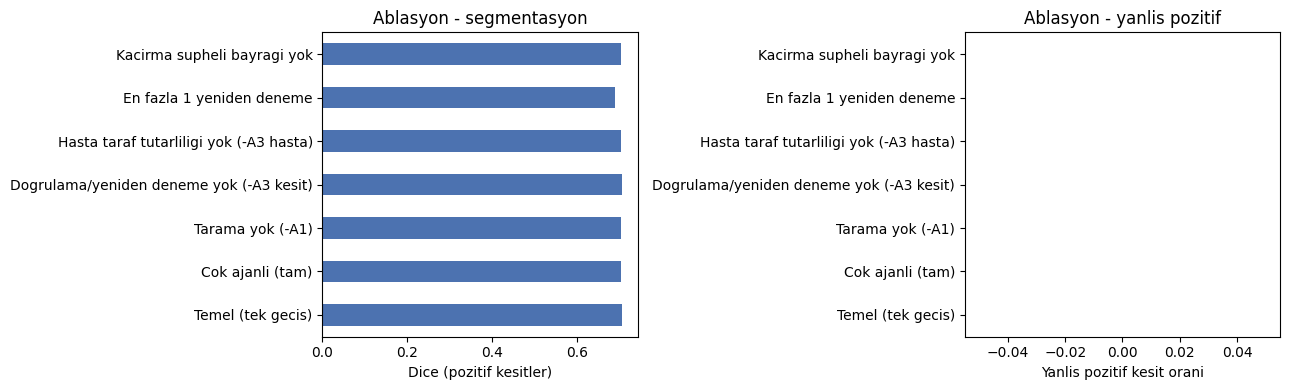

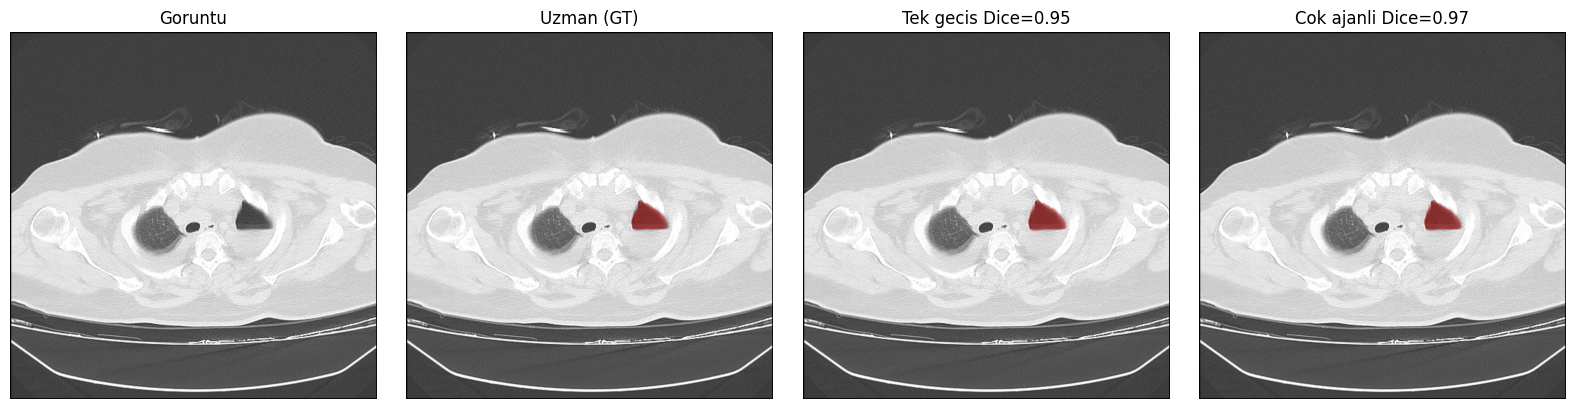

{'ajan': 'A1-Tarama', 'adim': 'siniflama', 'max_prob': 0.9995, 'karar': 'pozitif'}
{'ajan': 'A2-Segmentasyon', 'adim': 'segmentasyon', 'strateji': 'kutu_pay10_skor', 'unet_conf': 0.9995, 'sam_conf': 0.9288, 'uyum_iou': 0.8368, 'alan': 0.00591}
{'ajan': 'A3-Dogrulama', 'adim': 'kesit_denetimi', 'gecti': False, 'skor': 0.8, 'basarisiz': ['hava_yogunlugu'], 'guvenilirlik': 0.8071}
{'ajan': 'A2-Segmentasyon', 'adim': 'segmentasyon', 'strateji': 'kutu_pay10_uyum', 'unet_conf': 0.9995, 'sam_conf': 0.9163, 'uyum_iou': 0.8867, 'alan': 0.00557}
{'ajan': 'A3-Dogrulama', 'adim': 'kesit_denetimi', 'gecti': True, 'skor': 1.0, 'basarisiz': [], 'guvenilirlik': 0.7993}


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tablo.loc['Dice (pozitif kesit) ort.'].plot.barh(ax=ax[0], color='#4C72B0')
ax[0].set_xlabel('Dice (pozitif kesitler)'); ax[0].set_title('Ablasyon - segmentasyon')
tablo.loc['Yanlis pozitif kesit orani'].plot.barh(ax=ax[1], color='#C44E52')
ax[1].set_xlabel('Yanlis pozitif kesit orani'); ax[1].set_title('Ablasyon - yanlis pozitif')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/SEKIL_ablasyon.png', dpi=300); plt.show()

# Yeniden deneme yapilmis bir ornegi gorsellestir: ilk strateji vs nihai sonuc
ornek = mas_df[(mas_df.deneme > 1) & mas_df.gt_pos].sort_values('dice', ascending=False).head(1)
if len(ornek):
    o = ornek.iloc[0]
    jpg = os.path.join(po.RAW_DIR, o['patient_id'], o['slice']); png = jpg.replace('.jpg', '.png')
    img = po.load_image_rgb(jpg); gt = po.load_binary_mask(png)
    ilk = po.baseline_pipeline(img)['mask']
    ork = Orkestrator(CALIB, dict(TAM_SISTEM, use_report=False)); g = Gunluk()
    son = ork._kesit_isle(img, jpg, g)['seg']['mask']
    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    for a, (t, mm) in zip(ax, [('Goruntu', None), ('Uzman (GT)', gt), (f'Tek gecis Dice={po.segmentation_metrics(ilk, gt)["dice"]:.2f}', ilk),
                               (f'Cok ajanli Dice={po.segmentation_metrics(son, gt)["dice"]:.2f}', son)]):
        a.imshow(img if mm is None else po.make_overlay(img, mm)); a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/SEKIL_ornek_yeniden_deneme.png', dpi=300); plt.show()
    for k in g.kayitlar:
        print(k)